In [ ]:
import json
import os
import numpy as np
import pandas as pd

from sklearn.metrics import pairwise_distances


CENTRAL_FILE = (
    "all_encodings_original_GMDB_2026.csv"
)

# DECENTRAL_FILE = (
#     "all_encodings_stratified_GMDB_split_2026.csv"
# )

# DECENTRAL_FILE = (
#     "all_encodings_non-stratified_GMDB_male-female_split_2026.csv"
# )

DECENTRAL_FILE = (
    "all_encodings_non-stratified_GMDB_ethnicity_split_2026.csv"
)

DATA_PATH = "../data/GestaltMatcherDB/v1.1.0/gmdb_metadata"
LOOKUP_FILE = "../lookup_table_gmdb_v1.1.0.txt"

OUTPUT_DIR = "central_vs_decentral_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

output_file ="Central_vs_non-stratified_GMDB_ethnicity_split_summary.csv"

TOP_NS = [1, 5, 10, 30]


# ============================================================
# LOAD SYNDROME LOOKUP
# ============================================================

with open(LOOKUP_FILE) as f:
    synd_lookup_table = np.array(json.loads(f.readlines()[1]))


def syndrome_ids(labels):
    lookup = {sid: i for i, sid in enumerate(synd_lookup_table)}
    return np.array([lookup.get(x, x) for x in labels])


# ============================================================
# LOAD REPRESENTATIONS
# ============================================================

def load_representations(path):
    df = pd.read_csv(path, delimiter=";")

    df = (
        df.groupby("img_name")
        .agg(lambda x: list(x))
        .reset_index()
    )

    df["representations"] = df["representations"].apply(
        lambda x: np.array([json.loads(v) for v in x])
    )

    df["img_name"] = df["img_name"].str.split("_").str[0]

    return df


print("Loading representations...")

central_df = load_representations(CENTRAL_FILE)
decentral_df = load_representations(DECENTRAL_FILE)


# ============================================================
# GET REPRESENTATIONS FOR IMAGE IDS
# ============================================================

def get_representations(repr_df, image_ids):
    lookup = dict(zip(repr_df.img_name, repr_df.representations))

    ids = [str(x).strip() for x in image_ids]

    return (
        np.array([lookup[x] for x in ids]),
        np.array(ids)
    )


# ============================================================
# ALIGN DATA
# ============================================================

def align_data(gallery_df, test_df, test_synd_ids,
               central_df, decentral_df):

    gallery_df = gallery_df.copy()
    test_df = test_df.copy()

    gallery_df["image_id"] = gallery_df.image_id.astype(str).str.strip()
    test_df["image_id"] = test_df.image_id.astype(str).str.strip()

    central_ids = set(central_df.img_name.astype(str))
    decentral_ids = set(decentral_df.img_name.astype(str))

    gallery_df = gallery_df[
        gallery_df.image_id.isin(central_ids & decentral_ids)
    ].reset_index(drop=True)

    mask = (
        test_df.image_id.isin(central_ids)
        & test_df.image_id.isin(decentral_ids)
    )

    original_indices = np.where(mask)[0]

    test_df = test_df[mask].reset_index(drop=True)
    test_synd_ids = np.asarray(test_synd_ids)[original_indices]

    return gallery_df, test_df, test_synd_ids


# ============================================================
# GENERATE PREDICTIONS
# ============================================================

def predict(gallery_df, gallery_repr, test_repr):

    gallery_repr = np.asarray(gallery_repr, dtype=np.float32)
    test_repr = np.asarray(test_repr, dtype=np.float32)

    # Shape:
    # [images, 12, embedding_dimension]

    distances = np.stack([
        pairwise_distances(
            test_repr[:, i, :],
            gallery_repr[:, i, :],
            metric="cosine"
        )
        for i in range(test_repr.shape[1])
    ])

    # Average the 12 representation distances
    mean_distances = distances.mean(axis=0)

    ranked_indices = np.argsort(mean_distances, axis=1)

    # if "synd_id" in gallery_df:
    #     gallery_labels = gallery_df.synd_id.values
    # else:
    #     gallery_labels = gallery_df.label.values

    if "synd_id" in gallery_df:
        gallery_labels = gallery_df["synd_id"].to_numpy()
    else:
        gallery_labels = gallery_df["label"].to_numpy()

    ranked_labels = gallery_labels[ranked_indices]

    # Remove duplicate syndromes while preserving rank
    predictions = []

    for row in ranked_labels:
        seen = set()
        unique = []

        for label in row:
            key = label.item() if hasattr(label, "item") else label

            if key not in seen:
                seen.add(key)
                unique.append(label)

        predictions.append(unique)

    return np.array(predictions, dtype=object)


# ============================================================
# PAIRED METRICS
# ============================================================

def calculate_metrics(central_pred, decentral_pred, true_ids):

    rows = []

    true_ids = np.asarray(true_ids)

    for k in TOP_NS:

        central_correct = np.array([
            true_ids[i] in central_pred[i][:k]
            for i in range(len(true_ids))
        ])

        decentral_correct = np.array([
            true_ids[i] in decentral_pred[i][:k]
            for i in range(len(true_ids))
        ])

        both_correct = central_correct & decentral_correct
        both_wrong = ~central_correct & ~decentral_correct
        central_only = central_correct & ~decentral_correct
        decentral_only = ~central_correct & decentral_correct

        central_acc = central_correct.mean()
        decentral_acc = decentral_correct.mean()

        central_errors = ~central_correct
        decentral_errors = ~decentral_correct

        error_union = np.sum(
            central_errors | decentral_errors
        )

        error_overlap = (
            np.sum(central_errors & decentral_errors)
            / error_union
            if error_union
            else 0
        )

        rows.append({
            "top_k": k,
            "n": len(true_ids),

            "central_accuracy": central_acc,
            "decentral_accuracy": decentral_acc,
            "accuracy_difference":
                central_acc - decentral_acc,

            "both_correct": both_correct.mean(),
            "both_wrong": both_wrong.mean(),

            "central_only_correct":
                central_only.mean(),

            "decentral_only_correct":
                decentral_only.mean(),

            "disagreement_rate":
                np.mean(central_correct != decentral_correct),

            "error_overlap":
                error_overlap,

            "error_complementarity":
                1 - error_overlap,

            "directional_advantage":
                central_only.mean() - decentral_only.mean()
        })

    return pd.DataFrame(rows)


# ============================================================
# RUN
# ============================================================

def run_comparison(
    name,
    gallery_df,
    test_df,
    test_synd_ids
):

    print(f"\n{name}")

    gallery_df, test_df, test_synd_ids = align_data(
        gallery_df,
        test_df,
        test_synd_ids,
        central_df,
        decentral_df
    )

    central_gallery, central_gallery_ids = get_representations(
        central_df,
        gallery_df.image_id
    )

    decentral_gallery, decentral_gallery_ids = get_representations(
        decentral_df,
        gallery_df.image_id
    )

    central_test, central_test_ids = get_representations(
        central_df,
        test_df.image_id
    )

    decentral_test, decentral_test_ids = get_representations(
        decentral_df,
        test_df.image_id
    )

    if not np.array_equal(
        central_gallery_ids,
        decentral_gallery_ids
    ):
        raise ValueError("Central/Decentral gallery IDs are misaligned.")

    if not np.array_equal(
        central_test_ids,
        decentral_test_ids
    ):
        raise ValueError("Central/Decentral test IDs are misaligned.")

    central_pred = predict(
        gallery_df,
        central_gallery,
        central_test
    )

    decentral_pred = predict(
        gallery_df,
        decentral_gallery,
        decentral_test
    )

    metrics = calculate_metrics(
        central_pred,
        decentral_pred,
        test_synd_ids
    )

    metrics["experiment"] = name

    return metrics


# ============================================================
# LOAD GMDB DATA
# ============================================================

gallery_freq = pd.read_csv(
    os.path.join(
        DATA_PATH,
        "gmdb_frequent_gallery_images_v1.1.0.csv"
    )
)

test_freq = pd.read_csv(
    os.path.join(
        DATA_PATH,
        "gmdb_frequent_test_images_v1.1.0.csv"
    )
)

gallery_rare = pd.read_csv(
    os.path.join(
        DATA_PATH,
        "gmdb_rare_gallery_images_v1.1.0.csv"
    )
)

test_rare = pd.read_csv(
    os.path.join(
        DATA_PATH,
        "gmdb_rare_test_images_v1.1.0.csv"
    )
)


# ============================================================
# FREQUENT → FREQUENT
# ============================================================

gallery_freq["synd_id"] = syndrome_ids(
    gallery_freq.label
)

test_freq["synd_id"] = syndrome_ids(
    test_freq.label
)

gallery_rare["synd_id"] = syndrome_ids(
    gallery_rare.label
)

test_rare["synd_id"] = syndrome_ids(
    test_rare.label
)


test_freq_synd_ids = syndrome_ids(
    test_freq.label
)

freq_freq = run_comparison(
    "Frequent → Frequent",
    gallery_freq,
    test_freq,
    test_freq_synd_ids
)


# ============================================================
# COMBINED GALLERY
# ============================================================

gallery_combined = pd.concat(
    [gallery_freq, gallery_rare],
    ignore_index=True
)

num_splits = int(gallery_rare.split.max()) + 1


# ============================================================
# RARE → RARE
# ============================================================

rare_results = []

for split in range(num_splits):

    gallery = gallery_rare[
        gallery_rare.split == split
    ].copy()

    test = test_rare[
        test_rare.split == split
    ].copy()

    result = run_comparison(
        f"Rare → Rare split {split}",
        gallery,
        test,
        test.synd_id.values
        # test.label.values
    )

    rare_results.append(result)


rare_all = pd.concat(
    rare_results,
    ignore_index=True
)


rare_mean = (
    rare_all
    .groupby("top_k")
    .mean(numeric_only=True)
    .reset_index()
)
rare_ci = (
    rare_all
    .groupby("top_k")["error_overlap"]
    .agg(
        split_se="sem",
        n_splits="count"
    )
    .reset_index()
)

rare_ci["error_overlap_CI"] = (
    1.96 * rare_ci["split_se"]
)

rare_mean = rare_mean.merge(
    rare_ci[
        ["top_k", "error_overlap_CI", "n_splits"]
    ],
    on="top_k"
)


rare_mean["experiment"] = "Rare → Rare"


# ============================================================
# FREQUENT → FREQUENT + RARE
# ============================================================

freq_combined_results = []

for split in range(num_splits):

    gallery = gallery_combined.copy()

    gallery["split"] = gallery["split"].fillna(split)

    gallery = gallery[
        gallery.split == split
    ].copy()

    result = run_comparison(
        f"Frequent → Frequent+Rare split {split}",
        gallery,
        test_freq,
        test_freq_synd_ids
    )

    freq_combined_results.append(result)


freq_combined_all = pd.concat(
    freq_combined_results,
    ignore_index=True
)

freq_combined_mean = (
    freq_combined_all
    .groupby("top_k")
    .mean(numeric_only=True)
    .reset_index()
)

freq_combined_ci = (
    freq_combined_all
    .groupby("top_k")["error_overlap"]
    .agg(
        split_se="sem",
        n_splits="count"
    )
    .reset_index()
)

freq_combined_ci["error_overlap_CI"] = (
    1.96 * freq_combined_ci["split_se"]
)

freq_combined_mean = freq_combined_mean.merge(
    freq_combined_ci[
        ["top_k", "error_overlap_CI", "n_splits"]
    ],
    on="top_k"
)

freq_combined_mean["experiment"] = (
    "Frequent → Frequent+Rare"
)


# ============================================================
# RARE → FREQUENT + RARE
# ============================================================

rare_combined_results = []

for split in range(num_splits):

    gallery = gallery_combined.copy()

    gallery["split"] = gallery["split"].fillna(split)

    gallery = gallery[
        gallery.split == split
    ].copy()

    test = test_rare[
        test_rare.split == split
    ].copy()

    result = run_comparison(
        f"Rare → Frequent+Rare split {split}",
        gallery,
        test,
        test.synd_id.values
        # test.label.values
    )

    rare_combined_results.append(result)

print(rare_combined_results)

rare_combined_all = pd.concat(
    rare_combined_results,
    ignore_index=True
)

rare_combined_mean = (
    rare_combined_all
    .groupby("top_k")
    .mean(numeric_only=True)
    .reset_index()
)

rare_combined_ci = (
    rare_combined_all
    .groupby("top_k")["error_overlap"]
    .agg(
        split_se="sem",
        n_splits="count"
    )
    .reset_index()
)

rare_combined_ci["error_overlap_CI"] = (
    1.96 * rare_combined_ci["split_se"]
)

rare_combined_mean = rare_combined_mean.merge(
    rare_combined_ci[
        ["top_k", "error_overlap_CI", "n_splits"]
    ],
    on="top_k"
)

rare_combined_mean["experiment"] = (
    "Rare → Frequent+Rare"
)


# ============================================================
# FINAL SUMMARY
# ============================================================

final_summary = pd.concat(
    [
        freq_freq,
        rare_mean,
        freq_combined_mean,
        rare_combined_mean
    ],
    ignore_index=True
)

columns = [
    "experiment",
    "top_k",
    "central_accuracy",
    "decentral_accuracy",
    "accuracy_difference",
    "both_correct",
    "both_wrong",
    "central_only_correct",
    "decentral_only_correct",
    "disagreement_rate",
    "error_overlap",
    "error_overlap_CI",
    "error_complementarity",
    "directional_advantage"
]

final_summary = final_summary[columns]

final_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        output_file
    ),
    index=False
)


# ============================================================
# PRINT FINAL RESULT
# ============================================================

display_df = final_summary.copy()

percentage_columns = [
    "central_accuracy",
    "decentral_accuracy",
    "accuracy_difference",
    "both_correct",
    "both_wrong",
    "central_only_correct",
    "decentral_only_correct",
    "disagreement_rate",
    "error_overlap",
    "error_complementarity",
    "directional_advantage"
]

display_df[percentage_columns] *= 100

print("\n" + "=" * 100)
print("FINAL CENTRAL vs DECENTRAL SUMMARY")
print("=" * 100)

print(
    display_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

print(
    f"\nSaved to: {os.path.abspath(OUTPUT_DIR)}"
)

Loading representations...

Frequent → Frequent

Rare → Rare split 0

Rare → Rare split 1

Rare → Rare split 2

Rare → Rare split 3

Rare → Rare split 4

Rare → Rare split 5

Rare → Rare split 6

Rare → Rare split 7

Rare → Rare split 8

Rare → Rare split 9

Frequent → Frequent+Rare split 0

Frequent → Frequent+Rare split 1

Frequent → Frequent+Rare split 2

Frequent → Frequent+Rare split 3

Frequent → Frequent+Rare split 4

Frequent → Frequent+Rare split 5

Frequent → Frequent+Rare split 6

Frequent → Frequent+Rare split 7

Frequent → Frequent+Rare split 8

Frequent → Frequent+Rare split 9

Rare → Frequent+Rare split 0

Rare → Frequent+Rare split 1

Rare → Frequent+Rare split 2

Rare → Frequent+Rare split 3

Rare → Frequent+Rare split 4

Rare → Frequent+Rare split 5

Rare → Frequent+Rare split 6

Rare → Frequent+Rare split 7

Rare → Frequent+Rare split 8

Rare → Frequent+Rare split 9
[   top_k    n  central_accuracy  decentral_accuracy  accuracy_difference  \
0      1  391          0.

/home/bandyopadhyaya/GestaltMatcher_latest/env_gm/lib64/python3.6/site-packages/numpy/core/_asarray.py:83: UserWarning: Warning: converting a masked element to nan.
  return array(a, dtype, copy=False, order=order)


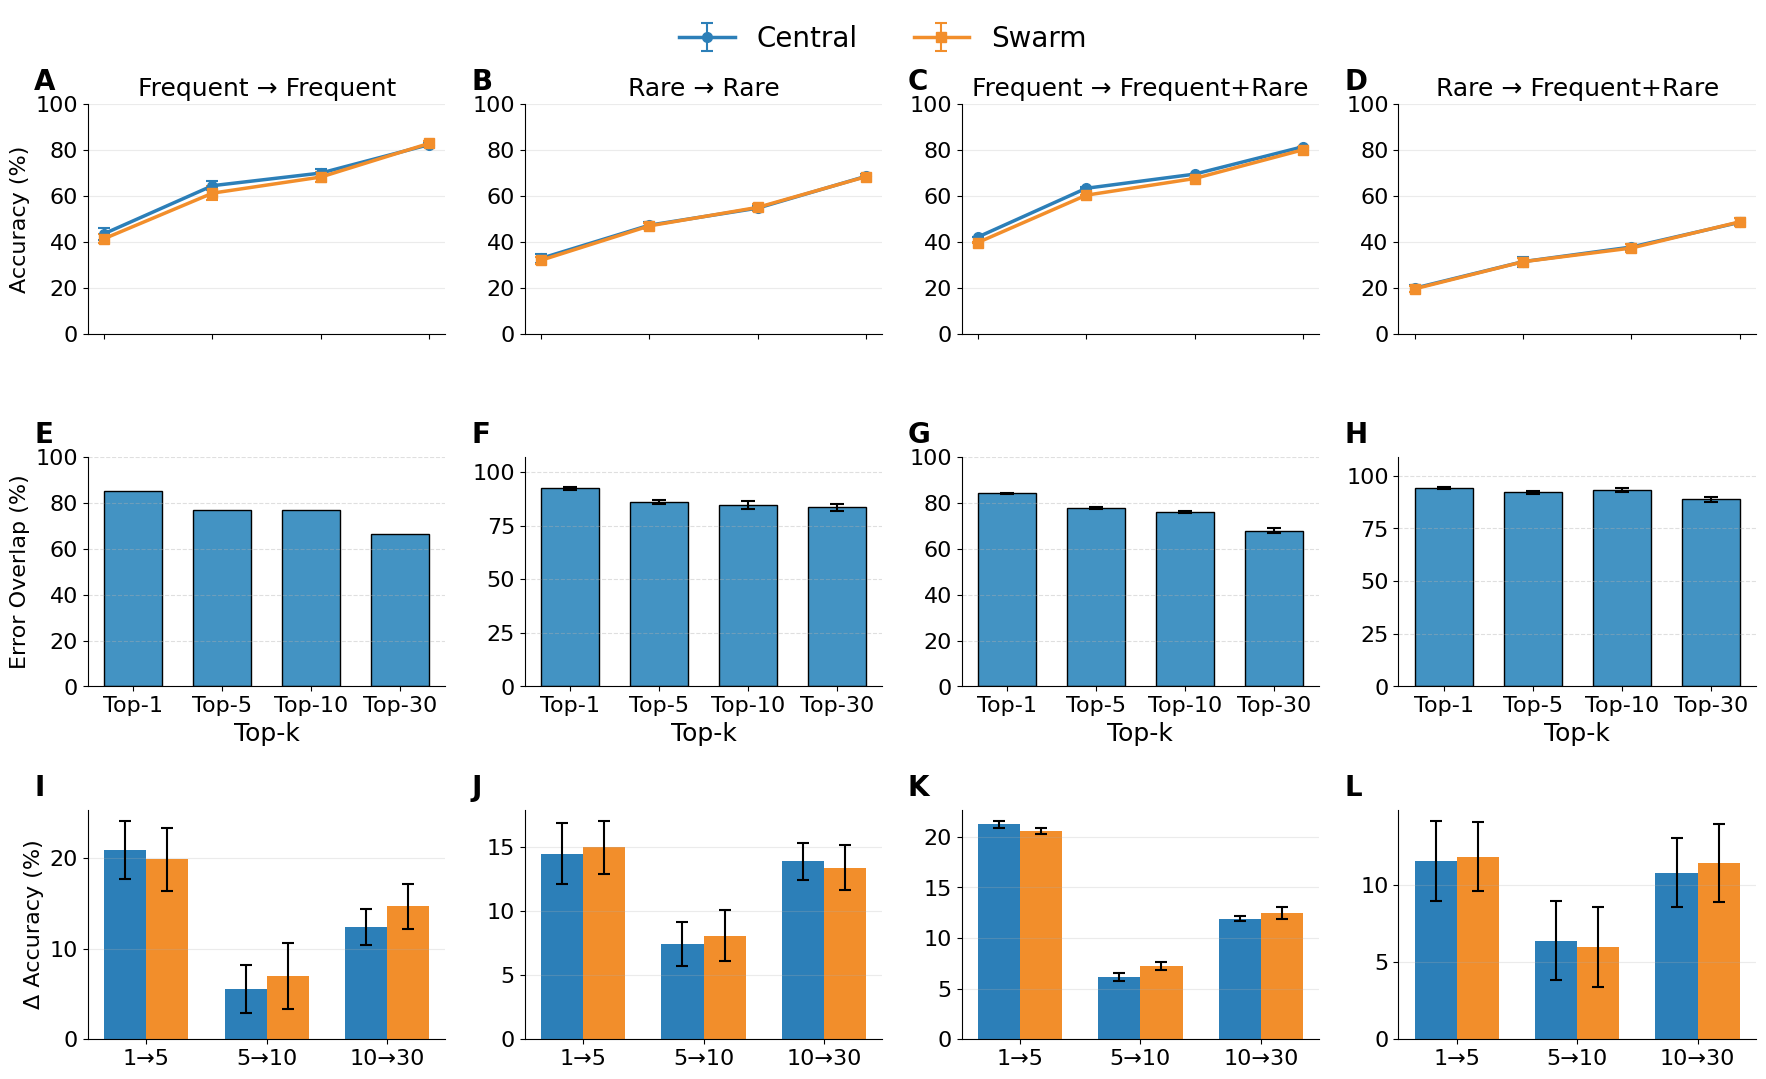

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os


# ============================================================
# Style
# ============================================================

plt.style.use("default")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 18,

    "axes.labelsize": 12,
    "axes.titlesize": 12,

    "xtick.labelsize": 16,
    "ytick.labelsize": 16,

    "legend.fontsize": 20,

    "axes.spines.top": False,
    "axes.spines.right": False
})


# ============================================================
# Colors / markers
# ============================================================

CENTRAL = "#2C7FB8"
SWARM = "#F28E2B"

MARK1 = "o"
MARK2 = "s"


# ============================================================
# Read CSV files
# ============================================================

central_df = pd.read_csv("ensemble_bootstrap_summary_original_GMDB.csv")
swarm_df = pd.read_csv("ensemble_bootstrap_summary_stratified_Swarm.csv")
error_file = "Central_vs_stratified_GMDB_split_summary.csv"
# ============================================================
# Experiments / panels
# ============================================================

experiments = [
    "Frequent → Frequent",
    "Rare → Rare",
    "Frequent → Frequent+Rare",
    "Rare → Frequent+Rare"
]

titles = [
    "Frequent → Frequent",
    "Rare → Rare",
    "Frequent → Frequent+Rare",
    "Rare → Frequent+Rare"
]

x = np.arange(4)
top_labels = ["Top-1", "Top-5", "Top-10", "Top-30"]


# ============================================================
# Helper function
# ============================================================

def get_data(df, experiment):
    """
    Return mean accuracy (%) and SE (%) for one experiment.
    """
    d = df[df["experiment"] == experiment].sort_values("top_n")

    mean = d["mean_accuracy_percent"].to_numpy()
    se = d["SE_percent"].to_numpy()

    return mean, se


# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(18, 11),
    sharex=False
)


# ============================================================
# Accuracy
# ============================================================

for i, experiment in enumerate(experiments):

    ax = axes[0, i]

    c, c_se = get_data(central_df, experiment)
    s, s_se = get_data(swarm_df, experiment)

    # Central
    ax.errorbar(
        x,
        c,
        yerr=c_se,
        color=CENTRAL,
        marker=MARK1,
        linewidth=2.5,
        markersize=7,
        capsize=4,
        capthick=1.5,
        elinewidth=1.5,
        label="Central"
    )

    # Swarm
    ax.errorbar(
        x,
        s,
        yerr=s_se,
        color=SWARM,
        marker=MARK2,
        linewidth=2.5,
        markersize=7,
        capsize=4,
        capthick=1.5,
        elinewidth=1.5,
        label="Swarm"
    )

    ax.set_ylim(0, 100)

    ax.set_xticks(x)
    ax.set_xticklabels(top_labels)

    ax.grid(axis="y", alpha=.25)

    ax.set_title(
        titles[i],
        fontsize=18
    )

    if i == 0:
        ax.set_ylabel("Accuracy (%)", fontsize=16)


# Hide x labels for top row
for ax in axes[0]:
    ax.tick_params(axis="x", labelbottom=False)


#########
# finding common Error percentage in models
OUTPUT_DIR = "central_vs_decentral_analysis"
SUMMARY_FILE = os.path.join(OUTPUT_DIR, error_file)
TOP_NS = [1, 5, 10, 30]
df = pd.read_csv(SUMMARY_FILE)

for i, experiment in enumerate(experiments):
    ax = axes[1, i]
    subset = df[df["experiment"] == experiment].copy()
    subset = subset[subset["top_k"].isin(TOP_NS)].sort_values("top_k")
    if subset.empty:
        raise ValueError(f"No data found for experiment: {experiment}")
    
    values = subset["error_overlap"].values * 100
    
    plot_values = (subset["error_overlap"].to_numpy() * 100)

    # 95% CI across splits
    plot_errors = (subset["error_overlap_CI"].to_numpy() * 100)
    x = np.arange(len(TOP_NS))

    # Bar plot
    ax.bar(
        x,
        plot_values,
        yerr=plot_errors,
        capsize=5,
        width=0.65,
        color="#4393C3",
        edgecolor="black",
        linewidth=1,
        error_kw={"elinewidth": 1.5, "capthick": 1.5},
    )

    # Formatting
    #ax.set_title(experiment, fontsize=13)
    ax.set_xticks(x)
    ax.set_xticklabels([f"Top-{k}" for k in TOP_NS])
    ax.set_xlabel("Top-k",fontsize=18)
    ax.set_ylim(0, max(100, np.max(plot_values + plot_errors) * 1.15))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.grid(axis="x", visible=False)



    if i == 0:
        ax.set_ylabel("Error Overlap (%)",fontsize=16)

# ============================================================
# Marginal Gain
# ============================================================

width = 0.35

for i, experiment in enumerate(experiments):

    ax = axes[2, i]

    c, c_se = get_data(central_df, experiment)
    s, s_se = get_data(swarm_df, experiment)

    # --------------------------------------------------------
    # Accuracy gain
    # --------------------------------------------------------

    c_gain = np.diff(c)
    s_gain = np.diff(s)

    # --------------------------------------------------------
    # Propagate SE for differences
    #
    # SE_delta = sqrt(SE_1^2 + SE_2^2)
    # --------------------------------------------------------

    c_gain_se = np.sqrt(
        c_se[:-1]**2 + c_se[1:]**2
    )

    s_gain_se = np.sqrt(
        s_se[:-1]**2 + s_se[1:]**2
    )

    xx = np.arange(3)

    # --------------------------------------------------------
    # Central
    # --------------------------------------------------------

    ax.bar(
        xx - width / 2,
        c_gain,
        width,
        color=CENTRAL,
        label="Central",
        yerr=c_gain_se,
        capsize=4,
        error_kw={
            "elinewidth": 1.5,
            "capthick": 1.5
        }
    )

    # --------------------------------------------------------
    # Swarm
    # --------------------------------------------------------

    ax.bar(
        xx + width / 2,
        s_gain,
        width,
        color=SWARM,
        label="Swarm",
        yerr=s_gain_se,
        capsize=4,
        error_kw={
            "elinewidth": 1.5,
            "capthick": 1.5
        }
    )

    ax.set_xticks(xx)
    ax.set_xticklabels([
        "1→5",
        "5→10",
        "10→30"
    ])

    ax.grid(axis="y", alpha=.25)

    if i == 0:
        ax.set_ylabel(
            "Δ Accuracy (%)",
            fontsize=16
        )


# ============================================================
# Panel labels
# ============================================================

letters = list("ABCDEFGHIJKL")

k = 0

for r in range(3):
    for c in range(4):

        axes[r, c].text(
            -0.15,
            1.06,
            letters[k],
            transform=axes[r, c].transAxes,
            fontsize=20,
            fontweight="bold"
        )

        k += 1


# ============================================================
# Common legend
# ============================================================

handles, legend_labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    ncol=2,
    loc="upper center",
    frameon=False,
    fontsize=20
)


# ============================================================
# Layout
# ============================================================

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


# ============================================================
# Save
# ============================================================

# plt.savefig(
#     "S2_topk_results.pdf",
#     dpi=600,
#     bbox_inches="tight"
# )

# plt.savefig(
#     "S2_topk_results.svg",
#     bbox_inches="tight"
# )

plt.show()